In [2]:
import supervision as sv


In [3]:
# from rfdetr import RFDETRNano
# from rfdetr import RFDETRMedium
from rfdetr import RFDETRLarge
# model = RFDETRNano()
# model = RFDETRMedium()
model = RFDETRLarge()

Loading pretrain weights


In [4]:
print("test")

test


In [5]:
model.train(
    dataset_dir="rfdetr_dataset", 
    epochs=40, 
    batch_size=1, 
    grad_accum_steps=16, 
    gradient_checkpointing=True,
    resolution=448,
    lr=0.0001,
    dropout=0.15,
    device="cuda", 
    save_dir="rfdetr_weights",
    tensorboard=True, 
    output_dir="output_large_2",
    weight_decay=0.0005,
    use_ema=True,
    early_stopping=True,
    early_stopping_patience=10,
    early_stopping_min_delta=0.001,
    early_stopping_use_ema=True
)

TensorBoard logging initialized. To monitor logs, use 'tensorboard --logdir output_large_2' and open http://localhost:6006/ in browser.
Not using distributed mode
git:
  sha: 2ac3ddd65e43c741084de46870968eb334a6493f, status: has uncommited changes, branch: main

Namespace(num_classes=12, grad_accum_steps=16, amp=True, lr=0.0001, lr_encoder=0.00015, batch_size=1, weight_decay=0.0005, epochs=40, lr_drop=100, clip_max_norm=0.1, lr_vit_layer_decay=0.8, lr_component_decay=0.7, do_benchmark=False, dropout=0.15, drop_path=0.0, drop_mode='standard', drop_schedule='constant', cutoff_epoch=0, pretrained_encoder=None, pretrain_weights='rf-detr-large.pth', pretrain_exclude_keys=None, pretrain_keys_modify_to_load=None, pretrained_distiller=None, encoder='dinov2_windowed_base', vit_encoder_num_layers=12, window_block_indexes=None, position_embedding='sine', out_feature_indexes=[2, 5, 8, 11], freeze_encoder=False, layer_norm=True, rms_norm=False, backbone_lora=False, force_no_pretrain=False, dec_laye

Epoch: [0]  [  0/656]  eta: 0:46:41  lr: 0.000100  class_error: 100.00  loss: 12.4091 (12.4091)  loss_ce: 2.6216 (2.6216)  loss_bbox: 0.0635 (0.0635)  loss_giou: 0.0896 (0.0896)  loss_ce_0: 2.2220 (2.2220)  loss_bbox_0: 0.1680 (0.1680)  loss_giou_0: 0.2009 (0.2009)  loss_ce_1: 2.3848 (2.3848)  loss_bbox_1: 0.0722 (0.0722)  loss_giou_1: 0.0961 (0.0961)  loss_ce_enc: 4.3767 (4.3767)  loss_bbox_enc: 0.0531 (0.0531)  loss_giou_enc: 0.0607 (0.0607)  loss_ce_unscaled: 2.6216 (2.6216)  class_error_unscaled: 100.0000 (100.0000)  loss_bbox_unscaled: 0.0127 (0.0127)  loss_giou_unscaled: 0.0448 (0.0448)  cardinality_error_unscaled: 3794.0000 (3794.0000)  loss_ce_0_unscaled: 2.2220 (2.2220)  loss_bbox_0_unscaled: 0.0336 (0.0336)  loss_giou_0_unscaled: 0.1005 (0.1005)  cardinality_error_0_unscaled: 3854.0000 (3854.0000)  loss_ce_1_unscaled: 2.3848 (2.3848)  loss_bbox_1_unscaled: 0.0144 (0.0144)  loss_giou_1_unscaled: 0.0481 (0.0481)  cardinality_error_1_unscaled: 3827.0000 (3827.0000)  loss_ce_enc_

Test:  [   0/2250]  eta: 0:38:22  class_error: 11.11  loss: 5.6393 (5.6393)  loss_ce: 0.7344 (0.7344)  loss_bbox: 0.0641 (0.0641)  loss_giou: 0.5911 (0.5911)  loss_ce_0: 0.7734 (0.7734)  loss_bbox_0: 0.0673 (0.0673)  loss_giou_0: 0.5942 (0.5942)  loss_ce_1: 0.7227 (0.7227)  loss_bbox_1: 0.0650 (0.0650)  loss_giou_1: 0.5891 (0.5891)  loss_ce_enc: 0.7617 (0.7617)  loss_bbox_enc: 0.0685 (0.0685)  loss_giou_enc: 0.6080 (0.6080)  loss_ce_unscaled: 0.7344 (0.7344)  class_error_unscaled: 11.1111 (11.1111)  loss_bbox_unscaled: 0.0128 (0.0128)  loss_giou_unscaled: 0.2955 (0.2955)  cardinality_error_unscaled: 273.0000 (273.0000)  loss_ce_0_unscaled: 0.7734 (0.7734)  loss_bbox_0_unscaled: 0.0135 (0.0135)  loss_giou_0_unscaled: 0.2971 (0.2971)  cardinality_error_0_unscaled: 273.0000 (273.0000)  loss_ce_1_unscaled: 0.7227 (0.7227)  loss_bbox_1_unscaled: 0.0130 (0.0130)  loss_giou_1_unscaled: 0.2946 (0.2946)  cardinality_error_1_unscaled: 270.0000 (270.0000)  loss_ce_enc_unscaled: 0.7617 (0.7617)  l

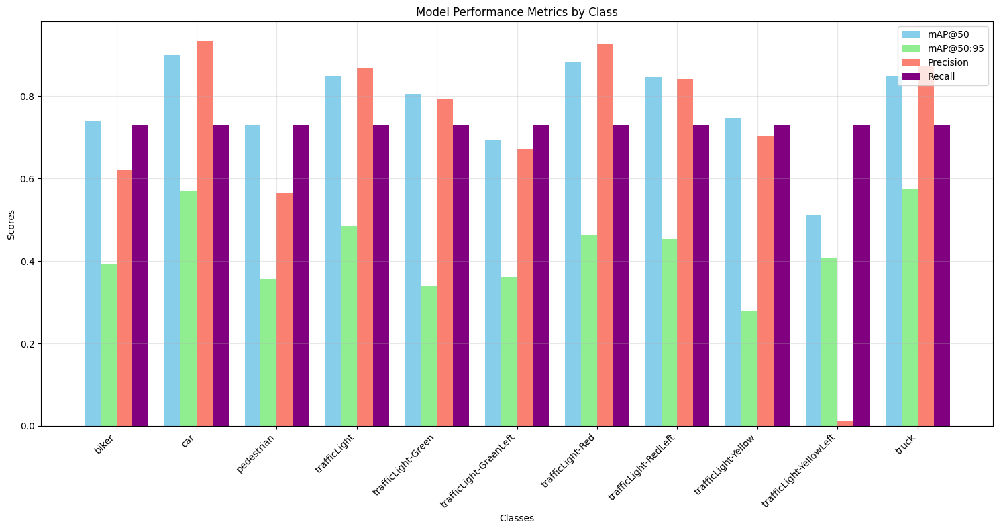

In [9]:
import json
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the results
with open('output/results.json', 'r') as f:
    results = json.load(f)

# Extract validation results
valid_results = results['class_map']['valid']

# Create a DataFrame
data = []
for item in valid_results:
    if item['class'] != 'all':  # Exclude the 'all' summary row
        data.append({
            'class': item['class'],
            'mAP@50': item['map@50'],
            'mAP@50:95': item['map@50:95'],
            'Precision': item['precision'],
            'Recall': item['recall']
        })

df = pd.DataFrame(data)

# Create the visualization
plt.figure(figsize=(15, 8))
x = range(len(df['class']))

# Plot bars
width = 0.2
plt.bar(x, df['mAP@50'], width, label='mAP@50', color='skyblue')
plt.bar([i + width for i in x], df['mAP@50:95'], width, label='mAP@50:95', color='lightgreen')
plt.bar([i + width * 2 for i in x], df['Precision'], width, label='Precision', color='salmon')
plt.bar([i + width * 3 for i in x], df['Recall'], width, label='Recall', color='purple')

# Customize the plot
plt.xlabel('Classes')
plt.ylabel('Scores')
plt.title('Model Performance Metrics by Class')
plt.xticks([i + width * 1.5 for i in x], df['class'], rotation=45, ha='right')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)

# Adjust layout to prevent label cutoff
plt.tight_layout()
plt.show()

In [11]:
from PIL import Image
import supervision as sv

image = Image.open("./rfdetr_dataset/valid/1478020224197266285.jpg")
detections = model.predict(image)

val_ds = sv.DetectionDataset.from_coco(
    images_directory_path="rfdetr_dataset/valid",
    annotations_path="rfdetr_dataset/valid/_annotations.coco.json"
)

In [12]:
import supervision as sv
from tqdm import tqdm
from supervision.metrics import MeanAveragePrecision

targets = []
predictions = []

for path, image, annotations in tqdm(val_ds):
    image = Image.open(path)
    detections = model.predict(image, threshold=0)

    targets.append(annotations)
    predictions.append(detections)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2250/2250 [02:10<00:00, 17.24it/s]


In [13]:
map_metric = MeanAveragePrecision()
map_result = map_metric.update(predictions, targets).compute()
print(map_result)

Average Precision (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.471
Average Precision (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.877
Average Precision (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.446
Average Precision (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.429
Average Precision (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ]                 = 0.623
Average Precision (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ]                 = 0.753


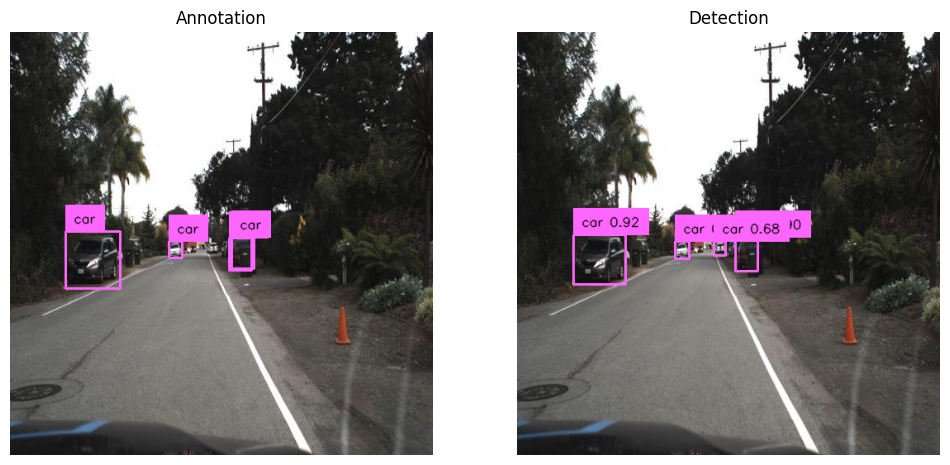

In [17]:
import supervision as sv
from PIL import Image

path, image, annotations = val_ds[15]
image = Image.open(path)

detections = model.predict(image, threshold=0.5)

text_scale = sv.calculate_optimal_text_scale(resolution_wh=image.size)
thickness = sv.calculate_optimal_line_thickness(resolution_wh=image.size)
color = sv.ColorPalette.from_hex([
    "#ffff00", "#ff9b00", "#ff66ff", "#3399ff", "#ff66b2", "#ff8080",
    "#b266ff", "#9999ff", "#66ffff", "#33ff99", "#66ff66", "#99ff00"
])

bbox_annotator = sv.BoxAnnotator(color=color,thickness=thickness)
label_annotator = sv.LabelAnnotator(
    color=color,
    text_color=sv.Color.BLACK,
    text_scale=text_scale)

annotations_labels = [
    f"{val_ds.classes[class_id]}"
    for class_id
    in annotations.class_id
]

detections_labels = [
    f"{val_ds.classes[class_id]} {confidence:.2f}"
    for class_id, confidence
    in zip(detections.class_id, detections.confidence)
]

annotation_image = image.copy()
annotation_image = bbox_annotator.annotate(annotation_image, annotations)
annotation_image = label_annotator.annotate(annotation_image, annotations, annotations_labels)

detections_image = image.copy()
detections_image = bbox_annotator.annotate(detections_image, detections)
detections_image = label_annotator.annotate(detections_image, detections, detections_labels)

sv.plot_images_grid(images=[annotation_image, detections_image], grid_size=(1, 2), titles=["Annotation", "Detection"])